# 02. Data exploration, cleaning and normalization (Chapter 4)

This notebook takes the IT data selected in notebook 01, explores it, cleans the texts and prepares them for the two search methods (BM25 and Sentence-BERT).

- **Input:** `data/processed/candidates_it_v1.csv`, `data/processed/jobs_it_v1.csv` (created by notebook 01).
- **Output:** `data/processed/candidates_it_v2.csv`, `data/processed/jobs_it_v2.csv`, new preview files in `data/samples/` and figures in `figures/`.

Steps:
1. Load data
2. Exploration: missing values, duplicates, text length, experience and English level
3. Search for problems in the texts (regex)
4. Cleaning
5. Before / after
6. Text for BM25
7. Save results
8. Software versions

In [53]:
import re
import sys
import unicodedata
from pathlib import Path

import ftfy
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

ROOT = Path("..")
PROCESSED = ROOT / "data" / "processed"
SAMPLES = ROOT / "data" / "samples"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
plt.style.use("default")  # white background in saved figures
plt.rcParams["font.size"] = 12

SEED = 5267
MIN_WORDS = 20          # shorter texts are removed

## 1. Load data

In [54]:
candidates = pd.read_csv(PROCESSED / "candidates_it_v1.csv")
jobs = pd.read_csv(PROCESSED / "jobs_it_v1.csv")

print("candidates:", candidates.shape)
print("jobs:      ", jobs.shape)

candidates: (132220, 11)
jobs:       (20000, 10)


## 2. Exploration

### 2.1 Missing values and duplicates

Only columns with at least one missing value are shown.

In [55]:
def missing_table(df):
    table = pd.DataFrame({
        "missing": df.isna().sum(),
        "missing_in_%": (df.isna().mean() * 100).round(1),
    })
    return table[table["missing"] > 0]


missing_table(candidates)

,missing,missing_in_%
Looking For,65387,49.5
Highlights,66909,50.6
English Level,387,0.3


In [56]:
missing_table(jobs)

,missing,missing_in_%
English Level,1178,5.9


Check for duplicates: the same id, the same text, and the same upper/lower case text and extra spaces are ignored.

In [57]:
def simple_text(s):
    return re.sub(r"\s+", " ", s.lower()).strip()


duplicates = pd.DataFrame({
    "same id": [candidates["id"].duplicated().sum(), jobs["id"].duplicated().sum()],
    "same text": [candidates["CV"].duplicated().sum(), jobs["Long Description"].duplicated().sum()],
    "same text (ignoring case and spaces)": [
        candidates["CV"].map(simple_text).duplicated().sum(),
        jobs["Long Description"].map(simple_text).duplicated().sum(),
    ],
}, index=["candidates", "jobs"])
duplicates

,same id,same text,same text (ignoring case and spaces)
candidates,0,0,0
jobs,0,0,0


Conclusion:
- There are no duplicated records, not even after ignoring case and spaces.
- `Highlights` and `Looking For` are empty for about half of the candidates. They are parts of `CV`, so the main text is never empty.
- `English Level` is missing for 0.3% of candidates and 5.9% of jobs.

### 2.2 Text length

Length is counted in words (split by spaces). `CV` is the main text of a candidate, `Long Description` is the main text of a job posting.

In [58]:
candidates["words"] = candidates["CV"].str.split().str.len()
jobs["words"] = jobs["Long Description"].str.split().str.len()

pd.DataFrame({
    "CV": candidates["words"].describe(),
    "Long Description": jobs["words"].describe(),
}).round(1)

,CV,Long Description
count,132220.0,20000.0
mean,128.7,246.5
std,92.7,136.3
min,1.0,19.0
25%,63.0,149.0
50%,102.0,221.0
75%,167.0,315.0
max,1061.0,2022.0


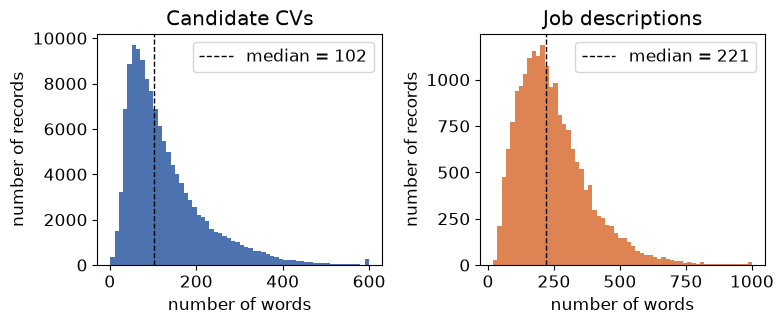

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))

axes[0].hist(candidates["words"].clip(upper=600), bins=60, color="#4C72B0")
axes[0].set_title("Candidate CVs")
axes[1].hist(jobs["words"].clip(upper=1000), bins=60, color="#DD8452")
axes[1].set_title("Job descriptions")

for ax, df in zip(axes, [candidates, jobs]):
    ax.axvline(df["words"].median(), color="black", linestyle="--", linewidth=1, label=f"median = {df['words'].median():.0f}")
    ax.set_xlabel("number of words")
    ax.set_ylabel("number of records")
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURES / "ch4_text_length.png", dpi=200)
plt.show()

Job descriptions are about two times longer than CVs (median 221 vs 102 words). Some CVs have only a few words, they are removed in step 4.

### 2.3 Experience and English level

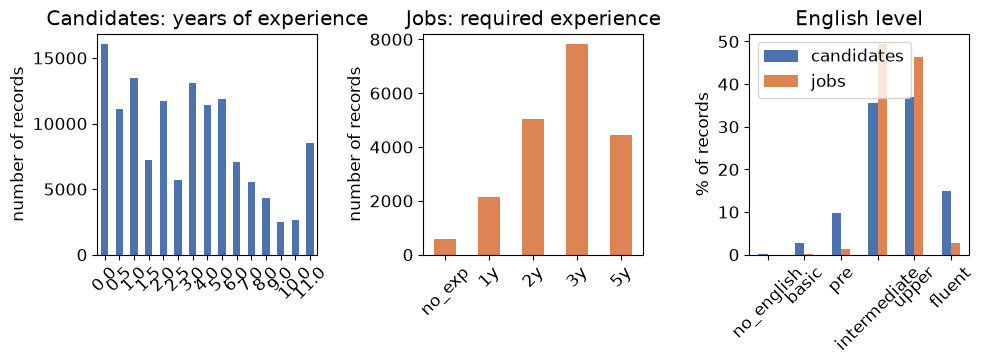

In [60]:
ENGLISH_ORDER = ["no_english", "basic", "pre", "intermediate", "upper", "fluent"]
JOB_EXP_ORDER = ["no_exp", "1y", "2y", "3y", "5y"]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.8))

candidates["Experience Years"].value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Candidates: years of experience")

jobs["Exp Years"].value_counts().reindex(JOB_EXP_ORDER).plot.bar(ax=axes[1], color="#DD8452")
axes[1].set_title("Jobs: required experience")

english = pd.DataFrame({
    "candidates": candidates["English Level"].value_counts(normalize=True),
    "jobs": jobs["English Level"].value_counts(normalize=True),
}).reindex(ENGLISH_ORDER).fillna(0) * 100
english.plot.bar(ax=axes[2], color=["#4C72B0", "#DD8452"])
axes[2].set_title("English level")
axes[2].set_ylabel("% of records")

for ax in axes[:2]:
    ax.set_ylabel("number of records")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(FIGURES / "ch4_experience_english.png", dpi=200)
plt.show()

## 3. Problems in the texts

The texts are searched with regular expressions. Each row of the table shows how many texts contain the problem at least once.

In [61]:
EMAIL = r"[\w.+-]+@[\w-]+\.[\w.]+"
LINK = r"https?://\S+|www\.\S+"
PHONE = r"\+\d[\d ()-]{7,}\d|(?<![\w.])\(?0\d{2}\)?[ -]?\d{3}[ -]?\d{2}[ -]?\d{2}(?![\w.])"
INVISIBLE = r"[\u200b\u200c\u200d\u200e\u200f\u2028\u2029\ufeff]"
NBSP = r"[\u00a0\u202f]"
BROKEN = r"â€|Ã[\u0080-\u00bf]|Ð[\u0080-\u00bf]"
CYRILLIC = r"[\u0400-\u04ff]"
MIXED_WORD = r"\b(?=\w*[a-zA-Z])(?=\w*[\u0400-\u04ff])\w+\b"

PATTERNS = {
    "e-mail": EMAIL,
    "link": LINK,
    "phone number": PHONE,
    "invisible characters": INVISIBLE,
    "non-breaking spaces": NBSP,
    "broken encoding": BROKEN,
    "Latin and Cyrillic in one word": MIXED_WORD,
    "Cyrillic letters": CYRILLIC,
}


def count_problems(df, col):
    return pd.Series({name: df[col].str.contains(p, regex=True).sum() for name, p in PATTERNS.items()})


def show_examples(df, col, pattern, n=3):
    for text in df.loc[df[col].str.contains(pattern, regex=True), col].head(n):
        m = re.search(pattern, text)
        print("...", repr(text[max(0, m.start() - 50): m.end() + 30]), "...")


problems_before = pd.DataFrame({
    "candidates": count_problems(candidates, "CV"),
    "jobs": count_problems(jobs, "Long Description"),
})
problems_before

,candidates,jobs
e-mail,0,0
link,1968,652
phone number,15,4
invisible characters,1203,498
non-breaking spaces,1017,653
broken encoding,0,1
Latin and Cyrillic in one word,2744,813
Cyrillic letters,6455,1528


Examples of such information. Phone numbers are not printed, only counted.

In [62]:
print("Links:")
show_examples(candidates, "CV", LINK)
print("\nBroken encoding:")
show_examples(jobs, "Long Description", BROKEN)
print("\nCyrillic letters:")
show_examples(candidates, "CV", CYRILLIC)

Links:
... 'mization of work and export.\r\n\r\nGraphic Designer\r\nwww.2Flame.org(Advertising/Marketing/PR Services)\r\n2020 - 2021\r\nWorke' ...
... 'list, 2d artist\r\nHyper-casual game Clew Cat\r\nAPK: https://goo.gl/GfV4Fu\r\nVideo: https://www.youtube.c' ...
... 'ame, illustrations for book covers.\r\n\r\nPortfolio: https://aizel_kon.artstation.com\nCreating game art: character ' ...

Broken encoding:
... 'icipation accessible in the digital age. The worldâ€™s leading nonprofits, associa' ...

Cyrillic letters:
... ' software - Maya, Blender.\r\nResponsibilities:\r\n1) Сollaborating with the art team' ...
... '2D АНИМАЦИЯ В SPINE(ArtCraft CG sc' ...
... 'Fire, MultiScatter, RenderMask, Populate: Terrain\nСложные задачи.' ...


Conclusion:
- No e-mails were found. Not that many phones have been left.
- Links are mostly portfolios, app stores and GitHub.
- All records are marked as English, but some texts contain Cyrillic letters.

### 3.1 Very short texts

In [63]:
print("candidates with less than", MIN_WORDS, "words:", (candidates["words"] < MIN_WORDS).sum())
print("jobs with less than", MIN_WORDS, "words:      ", (jobs["words"] < MIN_WORDS).sum())
print()
for text in candidates.loc[candidates["words"] < 10, "CV"].head(5):
    print(repr(text))

candidates with less than 20 words: 1686
jobs with less than 20 words:       1

'\nhigh+low poly modelling, texturing, rigging\n'
'\nCreating 3d models, sculpting, texturing,rigging, animations\n'
'\nDeveloped applications for insurance companies, banks, online stores, healthcare,\n'
'\nPlease check my CV file\n'
'\n5 years of Android development\nonly remote.'


### 3.2 Cyrillic text

**1. Cyrillic letters inside English words.** Some Cyrillic letters look the same as Latin ones (`С` and `C`, `о` and `o`). People type them by mistake when they switch the keyboard. For a person the word `Сreating` looks normal, but for BM25 it is a different word than `creating`. These letters are replaced with the Latin ones in step 4. The same is done for texts like `С#` or `С++`, where all Cyrillic letters look the same as Latin ones.

In [64]:
SIMILAR_LETTERS = "АВЕКМНОРСТХаеорсухіІјЈѕЅ"
TO_LATIN = str.maketrans(SIMILAR_LETTERS, "ABEKMHOPCTXaeopcyxiIjJsS")


def fix_similar_letters(text):
    text = re.sub(MIXED_WORD, lambda m: m.group().translate(TO_LATIN), text)
    if all(ch in SIMILAR_LETTERS for ch in re.findall(CYRILLIC, text)):
        text = text.translate(TO_LATIN)
    return text


mixed = candidates["CV"].str.findall(MIXED_WORD).explode().dropna()
print("words with Latin and Cyrillic letters in CVs:", len(mixed))
print(mixed.value_counts().head(10).to_dict())

words with Latin and Cyrillic letters in CVs: 3354
{'Сreating': 180, 'Сreated': 102, 'Сreation': 100, 'сreating': 65, 'Сompleted': 60, 'СSS': 46, 'Сommunication': 43, 'Сross': 40, 'Сurrently': 30, 'Сompany': 30}


**2. Cyrillic words.** After the fix above, the rest of the Cyrillic text is real words, not single similar letters. Often it is a separate line, but it is also often inside an English sentence, for example a company or a project name.

In [65]:
def cyrillic_lines(text):
    return [line for line in fix_similar_letters(text).split("\n") if re.search(CYRILLIC, line)]


lines = candidates["CV"].map(cyrillic_lines).explode().dropna()
for line in lines.sample(8, random_state=SEED):
    print(repr(line[:120]))

left_candidates = candidates["CV"].map(fix_similar_letters).str.contains(CYRILLIC)
left_jobs = jobs["Long Description"].map(fix_similar_letters).str.contains(CYRILLIC)
print()
print(f"CVs with Cyrillic after the fix:  {left_candidates.sum()} ({left_candidates.mean() * 100:.1f}%)")
print(f"jobs with Cyrillic after the fix: {left_jobs.sum()} ({left_jobs.mean() * 100:.1f}%)")

'I\'m working at "УКРТРАНСНАФТА" as an Intern Web Developer. I take part in developing new project modules and system impr'
'Продуктовая компания \\ Стартап.'
'- Интеграционное тестирование\r'
'1) "Web-разработчик 2021"  - author Ivan Petrychenko.\r'
'Реализация своих профессиональных навыков их развитие и обучение новых.'
'Улучшением качества продукта'
'Опыт в международжных проектах. Удаленная/проектная работа.'
'Працюю на MacOS'

CVs with Cyrillic after the fix:  3168 (2.4%)
jobs with Cyrillic after the fix: 616 (3.1%)


Deleting only the Cyrillic words would break such sentences, and deleting whole lines would also remove English parts. Both search methods and the language model in this work are used for English texts, so records that still have Cyrillic letters after the fix are removed completely (step 4). It is a small part of the data.

### 3.3 Non-developer roles

`Primary Keyword` shows the main technology, not the job itself. Some designers and artists use `Unity`, because they work in it, but they do not write code. Notebook 01 removed non-IT roles by `Primary Keyword`, so these records were not removed there. Since relevance labels are based only on `Primary Keyword`, a game designer would get the same label as a Unity developer. These records are found by the job title (`Position`) and removed, both CVs and job postings.

In [66]:
NOT_DEVELOPER = r"artist|animator|designer|illustrator|3d model"

candidates["non_developer"] = candidates["Position"].str.contains(NOT_DEVELOPER, case=False, na=False)
jobs["non_developer"] = jobs["Position"].str.contains(NOT_DEVELOPER, case=False, na=False)

print("candidates:", candidates["non_developer"].sum(), " jobs:", jobs["non_developer"].sum())
candidates.loc[candidates["non_developer"], ["Position", "Primary Keyword"]].value_counts().head(10)

candidates: 679  jobs: 79


Position              Primary Keyword
Game Designer         Unity              96
3D Artist             Unity              48
3d artist             Unity              42
Game designer         Unity              25
Technical Artist      Unity              14
2d artist             Unity              11
3D artist             Unity               8
web designer          JavaScript          7
Junior Game Designer  Unity               6
Technical artist      Unity               5
Name: count, dtype: int64

In [67]:
jobs.loc[jobs["non_developer"], ["Position", "Primary Keyword"]].value_counts().head(10)

Position                                       Primary Keyword
Game Designer                                  Unity              8
Technical Artist                               Unity              6
Senior Game Designer                           Unity              4
2D Animator                                    Unity              3
2D Artist                                      Unity              3
Level Designer                                 Unity              2
Character Technical Animator/Rigger            Unity              1
Layout Artist                                  Unity              1
Game Designer / Level Designer                 Unity              1
Game Designer for UNITY GAME (see SIMS VR/AR)  Unity              1
Name: count, dtype: int64

## 4. Cleaning

Text fixes (no rows are removed):
1. broken encoding is repaired with `ftfy`,
2. Unicode NFKC normalization (non-breaking spaces become normal spaces),
3. Cyrillic letters that look like Latin ones are replaced with Latin letters,
4. invisible characters are removed,
5. links, e-mails and phone numbers are replaced with `[LINK]`, `[EMAIL]` and `[PHONE]`,
6. line breaks and spaces are unified.

The fixes are applied to all text columns, not only to `CV` and `Long Description`, so personal data does not stay in other columns.

In [68]:
def clean_text(text):
    text = ftfy.fix_encoding(text)
    text = unicodedata.normalize("NFKC", text)
    text = fix_similar_letters(text)
    text = re.sub(r"[\u2028\u2029]", "\n", text)
    text = re.sub(INVISIBLE, "", text)
    text = re.sub(LINK, "[LINK]", text)
    text = re.sub(EMAIL, "[EMAIL]", text)
    text = re.sub(PHONE, "[PHONE]", text)
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


print(repr(clean_text("Senior\u00a0Python developer\u200b.\r\n\r\n\r\nPortfolio: https://example.com/me   Phone: +48 571 764 787")))

'Senior Python developer.\n\nPortfolio: [LINK] Phone: [PHONE]'


In [69]:
CANDIDATE_TEXT_COLUMNS = ["Position", "Highlights", "Moreinfo", "Looking For", "CV"]
JOB_TEXT_COLUMNS = ["Position", "Company Name", "Long Description"]

candidates_v1 = candidates.copy()
jobs_v1 = jobs.copy()

for col in CANDIDATE_TEXT_COLUMNS:
    candidates[col] = candidates[col].map(clean_text, na_action="ignore")
for col in JOB_TEXT_COLUMNS:
    jobs[col] = jobs[col].map(clean_text, na_action="ignore")

candidates["words"] = candidates["CV"].str.split().str.len()
jobs["words"] = jobs["Long Description"].str.split().str.len()

Removing records. The number of records is saved after each step.

In [70]:
steps = []


def log_step(name):
    steps.append({"step": name, "candidates": len(candidates), "jobs": len(jobs)})


log_step("selected IT data (v1)")

candidates = candidates[~candidates["CV"].map(simple_text).duplicated()]
jobs = jobs[~jobs["Long Description"].map(simple_text).duplicated()]
log_step("duplicates removed")

candidates = candidates[candidates["words"] >= MIN_WORDS]
jobs = jobs[jobs["words"] >= MIN_WORDS]
log_step(f"texts shorter than {MIN_WORDS} words removed")

candidates = candidates[~candidates["CV"].str.contains(CYRILLIC)]
jobs = jobs[~jobs["Long Description"].str.contains(CYRILLIC)]
log_step("texts with Cyrillic words removed")

candidates = candidates[~candidates["non_developer"]]
jobs = jobs[~jobs["non_developer"]]
log_step("non-developer roles removed")

candidates = candidates.reset_index(drop=True)
jobs = jobs.reset_index(drop=True)

steps = pd.DataFrame(steps)
steps["removed candidates"] = -steps["candidates"].diff().fillna(0).astype(int)
steps["removed jobs"] = -steps["jobs"].diff().fillna(0).astype(int)
steps

,step,candidates,jobs,removed candidates,removed jobs
0,selected IT data (v1),132220,20000,0,0
1,duplicates removed,132220,20000,0,0
2,texts shorter than 20 words removed,130533,19999,1687,1
3,texts with Cyrillic words removed,127378,19383,3155,616
4,non-developer roles removed,126734,19306,644,77


In total 5,486 CVs (4.1%) and 694 job postings (3.5%) were removed. Most of them were removed because of Cyrillic text.

## 5. Before / after

In [71]:
problems_after = pd.DataFrame({
    "candidates": count_problems(candidates, "CV"),
    "jobs": count_problems(jobs, "Long Description"),
})
before_after = pd.concat({"before": problems_before, "after": problems_after}, axis=1)
before_after

before            after     
                               candidates  jobs candidates jobs
e-mail                                  0     0          0    0
link                                 1968   652          0    0
phone number                           15     4          0    0
invisible characters                 1203   498          0    0
non-breaking spaces                  1017   653          0    0
broken encoding                         0     1          0    0
Latin and Cyrillic in one word       2744   813          0    0
Cyrillic letters                     6455  1528          0    0

After cleaning all problems are zero, so they are shown only in the table above. The figure below shows which part of each role family was removed by cleaning.

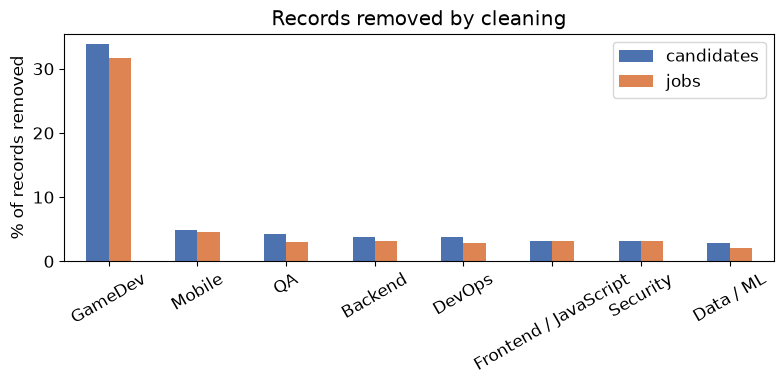

In [72]:
removed = pd.DataFrame({
    "candidates": 100 - candidates["role_family"].value_counts() / candidates_v1["role_family"].value_counts() * 100,
    "jobs": 100 - jobs["role_family"].value_counts() / jobs_v1["role_family"].value_counts() * 100,
}).round(1).sort_values("candidates", ascending=False)

ax = removed.plot.bar(figsize=(8, 4), color=["#4C72B0", "#DD8452"])
ax.set_title("Records removed by cleaning")
ax.set_ylabel("% of records removed")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(FIGURES / "ch4_removed_by_family.png", dpi=200)
plt.show()

Example of one CV before and after cleaning:

In [73]:
changed = candidates_v1["CV"].str.contains(LINK, regex=True) & candidates_v1["CV"].str.contains(INVISIBLE, regex=True)
example_id = candidates_v1.loc[changed, "id"].iloc[0]

print("BEFORE:\n", repr(candidates_v1.loc[candidates_v1["id"] == example_id, "CV"].iloc[0][:400]))
print("\nAFTER:\n", repr(candidates.loc[candidates["id"] == example_id, "CV"].iloc[0][:400]))

BEFORE:
 '• Full-stack development\r\n• More than 10 apps created\r\n• Work with Under Armour®\u200e and HTC \r\n• Apps on Play Market and App Store:\r\n     https://play.google.com/store/apps/details?id=com.acentas.hr_monitor\r\n     https://play.google.com/store/apps/details?id=com.ahrma.micro_pallet\r\n     https://itunes.apple.com/us/app/ahrma-micro-pallet/id1121560328?mt=8\nAndroid SDK, iOS SDK, Android Studio, NetBeans'

AFTER:
 '• Full-stack development\n• More than 10 apps created\n• Work with Under Armour® and HTC\n• Apps on Play Market and App Store:\n[LINK]\n[LINK]\n[LINK]\nAndroid SDK, iOS SDK, Android Studio, NetBeans, Xcode, Java, C, Objective-C, XML, Patterns, data structures, Algorithms, Git, ACRA, JSON, Gson, Spring, Bluetooth LE, AndroidPlot, SQLite.\n• Interesting projects\n• Professional growth'


## 6. Text for BM25

BM25 searches for exact words, so its text is normalized:
1. lowercase,
2. split into words (punctuation is removed, but `c++`, `c#`, `.net` and `node.js` stay one word),
3. stop words are removed (English list from scikit-learn, 318 words),
4. placeholders `[LINK]`, `[EMAIL]`, `[PHONE]` are removed.

The original text is not changed. The result is saved in a new column (`CV_bm25`, `Long Description_bm25`). Sentence-BERT and the language model use the original cleaned text, because they need full sentences.

In [74]:
TOKEN = r"\.?[a-z0-9][a-z0-9+#]*(?:[.\-][a-z0-9+#]+)*"
PLACEHOLDERS = r"\[(?:link|email|phone)\]"


def bm25_tokens(text):
    text = re.sub(PLACEHOLDERS, " ", text.lower())
    return [w for w in re.findall(TOKEN, text) if w not in ENGLISH_STOP_WORDS]


print(len(ENGLISH_STOP_WORDS), "stop words")
example = "Experienced Python developer, working with Django, Node.js, C++ and .NET for 5 years."
print(example)
print(bm25_tokens(example))

318 stop words
Experienced Python developer, working with Django, Node.js, C++ and .NET for 5 years.
['experienced', 'python', 'developer', 'working', 'django', 'node.js', 'c++', '.net', '5', 'years']


In [75]:
candidates["CV_bm25"] = candidates["CV"].map(lambda t: " ".join(bm25_tokens(t)))
jobs["Long Description_bm25"] = jobs["Long Description"].map(lambda t: " ".join(bm25_tokens(t)))

candidates["bm25_words"] = candidates["CV_bm25"].str.split().str.len()
jobs["bm25_words"] = jobs["Long Description_bm25"].str.split().str.len()

pd.DataFrame({
    "CV words": candidates["words"].describe(),
    "CV words for BM25": candidates["bm25_words"].describe(),
    "job words": jobs["words"].describe(),
    "job words for BM25": jobs["bm25_words"].describe(),
}).round(1)

,CV words,CV words for BM25,job words,job words for BM25
count,126734.0,126734.0,19306.0,19306.0
mean,129.8,86.1,245.7,155.2
std,92.2,60.9,135.4,82.5
min,20.0,6.0,21.0,15.0
25%,64.0,43.0,148.0,96.0
50%,103.0,68.0,220.0,140.0
75%,168.0,111.0,314.0,198.0
max,1061.0,679.0,2022.0,1113.0


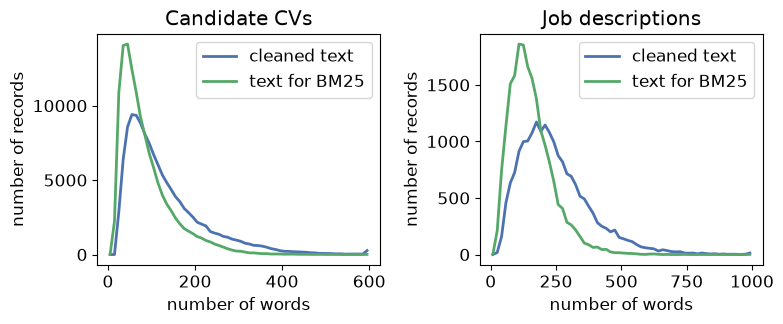

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))

for ax, df, title, limit in [(axes[0], candidates, "Candidate CVs", 600), (axes[1], jobs, "Job descriptions", 1000)]:
    bins = np.linspace(0, limit, 61)
    centers = (bins[:-1] + bins[1:]) / 2
    for col, label, color in [("words", "cleaned text", "#4C72B0"), ("bm25_words", "text for BM25", "#55A868")]:
        counts, _ = np.histogram(df[col].clip(upper=limit), bins=bins)
        ax.plot(centers, counts, linewidth=2, label=label, color=color)
    ax.set_title(title)
    ax.set_xlabel("number of words")
    ax.set_ylabel("number of records")
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURES / "ch4_bm25_length.png", dpi=200)
plt.show()

After normalization the BM25 text is about one third shorter, because stop words and punctuation are removed.

## 7. Save results

- `data/processed/*_v2.csv` - cleaned data with the extra BM25 column. Helper columns (word counts, non-developer flag) are not saved.
- `data/samples/*_sample.csv` - 50 rows of each cleaned file.

In [77]:
HELPER_COLUMNS = ["words", "bm25_words", "non_developer"]
candidates_v2 = candidates.drop(columns=HELPER_COLUMNS)
jobs_v2 = jobs.drop(columns=HELPER_COLUMNS)

candidates_v2.to_csv(PROCESSED / "candidates_it_v2.csv", index=False, encoding="utf-8")
jobs_v2.to_csv(PROCESSED / "jobs_it_v2.csv", index=False, encoding="utf-8")

candidates_v2.sample(50, random_state=SEED).to_csv(SAMPLES / "djinni_candidates_sample.csv", index=False, encoding="utf-8")
jobs_v2.sample(50, random_state=SEED).to_csv(SAMPLES / "djinni_jobs_sample.csv", index=False, encoding="utf-8")

for path in sorted(PROCESSED.glob("*_v2.csv")) + sorted(SAMPLES.glob("*.csv")):
    print(f"{path.relative_to(ROOT)}  {path.stat().st_size / 1e6:.1f} MB")

data\processed\candidates_it_v2.csv  320.6 MB
data\processed\jobs_it_v2.csv  59.9 MB
data\samples\djinni_candidates_sample.csv  0.1 MB
data\samples\djinni_jobs_sample.csv  0.2 MB


## 8. Software versions

In [78]:
pd.Series({
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "scikit-learn": sklearn.__version__,
    "ftfy": ftfy.__version__,
}, name="version").to_frame()

,version
Python,3.14.5
pandas,3.1.0
numpy,2.5.4
matplotlib,3.11.2
scikit-learn,1.9.1
ftfy,6.3.1
